## Step 1: Setup

In [ ]:
from pathlib import Path
import json
import shutil
from collections import Counter, defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt

coco_root = Path(r"C:\Users\shiif\Downloads\coco2017")
annotations_dir = coco_root / "annotations"

train_annotation_path = annotations_dir / "instances_train2017.json"
val_annotation_path = annotations_dir / "instances_val2017.json"

print("Train annotations path:", train_annotation_path)
print("Val annotations path:  ", val_annotation_path)


Train annotations path: C:\Users\shiif\Downloads\coco2017\annotations\instances_train2017.json
Val annotations path:   C:\Users\shiif\Downloads\coco2017\annotations\instances_val2017.json


## Step 2: Compute COCO Statistics

In [2]:
# --- Load one COCO annotation file ---
def load_coco_annotations(json_path):
    with open(json_path, "r") as f:
        return json.load(f)


# --- Compute per-class image counts and instance counts ---
def compute_class_statistics(coco_data):
    category_id_to_name = {cat["id"]: cat["name"] for cat in coco_data["categories"]}

    instance_counts = Counter()            # class_name -> total instance count
    images_per_class = defaultdict(set)    # class_name -> unique image_ids containing it

    for ann in tqdm(coco_data["annotations"], desc="Processing annotations"):
        class_name = category_id_to_name[ann["category_id"]]
        instance_counts[class_name] += 1
        images_per_class[class_name].add(ann["image_id"])

    image_counts = {name: len(ids) for name, ids in images_per_class.items()}
    return instance_counts, image_counts


In [3]:
# --- Load both annotation files and compute statistics ---
train_data = load_coco_annotations(train_annotation_path)
val_data = load_coco_annotations(val_annotation_path)

train_instance_counts, train_image_counts = compute_class_statistics(train_data)
val_instance_counts, val_image_counts = compute_class_statistics(val_data)

# --- Build one statistics table for all classes ---
all_class_names = sorted(cat["name"] for cat in train_data["categories"])

coco_stats_df = pd.DataFrame([
    {
        "Class": name,
        "Train Images": train_image_counts.get(name, 0),
        "Train Instances": train_instance_counts.get(name, 0),
        "Val Images": val_image_counts.get(name, 0),
        "Val Instances": val_instance_counts.get(name, 0),
    }
    for name in all_class_names
]).sort_values(by="Train Instances", ascending=False).reset_index(drop=True)

print("COCO class statistics (sorted by Train Instances):")
coco_stats_df


Processing annotations: 100%|██████████| 36781/36781 [00:00<00:00, 1768449.54it/s]


COCO class statistics (sorted by Train Instances):


,Class,Train Images,Train Instances,Val Images,Val Instances
0,person,64115,262465,2693,11004
1,car,12251,43867,535,1932
2,chair,12774,38491,580,1791
3,book,5332,24715,230,1161
4,bottle,8501,24342,379,1025
...,...,...,...,...,...
75,scissors,947,1481,28,36
76,bear,960,1294,49,71
77,parking meter,705,1285,37,60
78,toaster,217,225,8,9


## Step 3: Choose Five Classes

In [4]:
# --- Candidate classes and minimum thresholds ---
candidate_classes = ["car", "chair", "dog", "handbag", "truck", "cup", "bottle", "horse", "backpack"]
MIN_TRAIN_INSTANCES = 4000
MIN_VAL_INSTANCES = 500

# --- Filter candidates that meet both thresholds, then take the top 5 by Train Instances ---
qualifying_df = coco_stats_df[
    coco_stats_df["Class"].isin(candidate_classes)
    & (coco_stats_df["Train Instances"] >= MIN_TRAIN_INSTANCES)
    & (coco_stats_df["Val Instances"] >= MIN_VAL_INSTANCES)
].sort_values(by="Train Instances", ascending=False)

selected_classes = qualifying_df["Class"].head(5).tolist()

print("Selected classes:")
for name in selected_classes:
    print(" -", name)

# --- Show their stats ---
coco_stats_df[coco_stats_df["Class"].isin(selected_classes)].reset_index(drop=True)


Selected classes:
 - car
 - chair
 - bottle
 - cup
 - handbag


,Class,Train Images,Train Instances,Val Images,Val Instances
0,car,12251,43867,535,1932
1,chair,12774,38491,580,1791
2,bottle,8501,24342,379,1025
3,cup,9189,20650,390,899
4,handbag,6841,12354,292,540


## Step 4: Create Dataset Directory

In [5]:
# --- Dataset root ---
dataset_root = Path("datasets") / "coco_instance_balanced5"

# --- Start clean: remove any old version of this dataset ---
if dataset_root.exists():
    shutil.rmtree(dataset_root)

# --- Create the folder structure ---
for folder in [
    dataset_root / "images" / "train",
    dataset_root / "images" / "val",
    dataset_root / "labels" / "train",
    dataset_root / "labels" / "val",
]:
    folder.mkdir(parents=True, exist_ok=True)

print("Dataset folder structure created at:", dataset_root.resolve())


Dataset folder structure created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5


## Step 5: Build Class and Image Lookups

In [6]:
# --- class name -> new index (0 to 4), in the order of selected_classes ---
class_name_to_index = {name: idx for idx, name in enumerate(selected_classes)}

# --- COCO category_id -> new index (only for our 5 selected classes) ---
category_id_to_name = {cat["id"]: cat["name"] for cat in train_data["categories"]}
category_id_to_new_index = {
    cat_id: class_name_to_index[name]
    for cat_id, name in category_id_to_name.items()
    if name in class_name_to_index
}

# --- image_id -> file_name/width/height, for train and val ---
def build_image_info(coco_data):
    return {img["id"]: {"file_name": img["file_name"], "width": img["width"], "height": img["height"]}
            for img in coco_data["images"]}

train_image_info = build_image_info(train_data)
val_image_info = build_image_info(val_data)

print("Class index mapping:")
for name, idx in class_name_to_index.items():
    print(f"  {idx}: {name}")


Class index mapping:
  0: car
  1: chair
  2: bottle
  3: cup
  4: handbag


## Step 6: Filter Annotations

In [16]:
# --- Keep only annotations for our 5 selected classes, grouped by image_id ---
def filter_annotations_by_image(coco_data, category_id_to_new_index):
    selected_ids = set(category_id_to_new_index.keys())
    annotations_by_image = defaultdict(list)

    for ann in tqdm(coco_data["annotations"], desc="Filtering annotations"):
        if ann["category_id"] in selected_ids:
            annotations_by_image[ann["image_id"]].append(ann)

    return annotations_by_image

train_annotations_by_image = filter_annotations_by_image(train_data, category_id_to_new_index)
val_annotations_by_image = filter_annotations_by_image(val_data, category_id_to_new_index)

print("Training images with a selected class:  ", len(train_annotations_by_image))
print("Validation images with a selected class:", len(val_annotations_by_image))


Filtering annotations: 100%|██████████| 36781/36781 [00:00<00:00, 417106.78it/s]

Training images with a selected class:   38555
Validation images with a selected class: 1699


## Step 7: Copy Images and Write YOLO Labels

In [17]:
# --- Convert one COCO bbox [x_min, y_min, w, h] to YOLO [x_center, y_center, w, h] (normalized) ---
def coco_bbox_to_yolo(bbox, image_width, image_height):
    x_min, y_min, box_width, box_height = bbox
    x_center = (x_min + box_width / 2) / image_width
    y_center = (y_min + box_height / 2) / image_height
    return x_center, y_center, box_width / image_width, box_height / image_height


# --- Copy images + write labels for one split (train or val) ---
def build_dataset_split(split_name, source_images_dir, image_info, annotations_by_image, category_id_to_new_index):
    destination_images_dir = dataset_root / "images" / split_name
    destination_labels_dir = dataset_root / "labels" / split_name

    for image_id, annotations in tqdm(annotations_by_image.items(), desc=f"Writing {split_name} set"):
        info = image_info[image_id]
        file_name = info["file_name"]

        # Copy the image
        shutil.copy(source_images_dir / file_name, destination_images_dir / file_name)

        # Build the label lines for this image
        label_lines = []
        for ann in annotations:
            class_index = category_id_to_new_index[ann["category_id"]]
            x_c, y_c, w, h = coco_bbox_to_yolo(ann["bbox"], info["width"], info["height"])
            label_lines.append(f"{class_index} {x_c:.6f} {y_c:.6f} {w:.6f} {h:.6f}")

        # Write the label file (same base name as the image)
        label_path = destination_labels_dir / (Path(file_name).stem + ".txt")
        with open(label_path, "w") as f:
            f.write("\n".join(label_lines))


build_dataset_split("train", coco_root / "train2017", train_image_info,
                     train_annotations_by_image, category_id_to_new_index)
build_dataset_split("val", coco_root / "val2017", val_image_info,
                     val_annotations_by_image, category_id_to_new_index)

print("Dataset created at:", dataset_root.resolve())


Writing val set: 100%|██████████| 1699/1699 [00:09<00:00, 174.83it/s]

Dataset created at: C:\Users\shiif\Downloads\yoloduke\datasets\coco_instance_balanced5


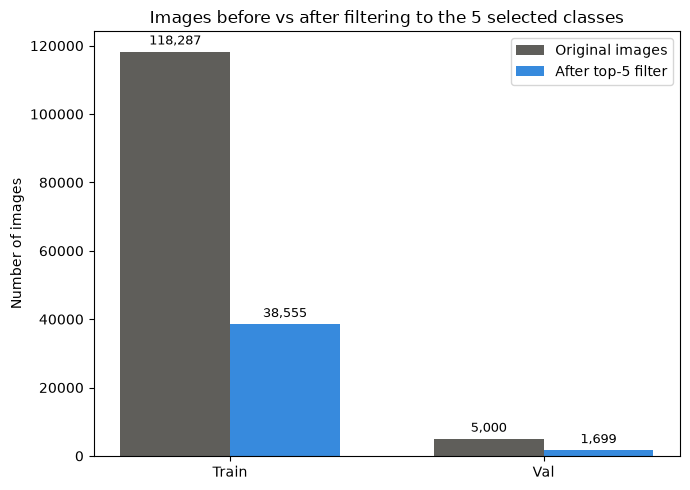

In [10]:
# --- Bar chart: original images vs images remaining after selecting top 5 classes ---

# Total images in the raw COCO dataset (every image, regardless of class)
original_train_images = len(train_data["images"])
original_val_images = len(val_data["images"])

# Images that survived filtering (i.e. contain at least one of the 5 selected classes)
filtered_train_images = len(train_annotations_by_image)
filtered_val_images = len(val_annotations_by_image)

splits = ["Train", "Val"]
original_counts = [original_train_images, original_val_images]
filtered_counts = [filtered_train_images, filtered_val_images]

x_positions = range(len(splits))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))

orig_bars = ax.bar([x - bar_width/2 for x in x_positions], original_counts,
                    width=bar_width, label="Original images", color="#5F5E5A")
filt_bars = ax.bar([x + bar_width/2 for x in x_positions], filtered_counts,
                    width=bar_width, label="After top-5 filter", color="#378ADD")

# --- Print exact counts above each bar ---
for bar in list(orig_bars) + list(filt_bars):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + max(original_counts)*0.01,
            f"{int(height):,}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(list(x_positions))
ax.set_xticklabels(splits)
ax.set_ylabel("Number of images")
ax.set_title("Images before vs after filtering to the 5 selected classes")
ax.legend()

plt.tight_layout()
plt.show()

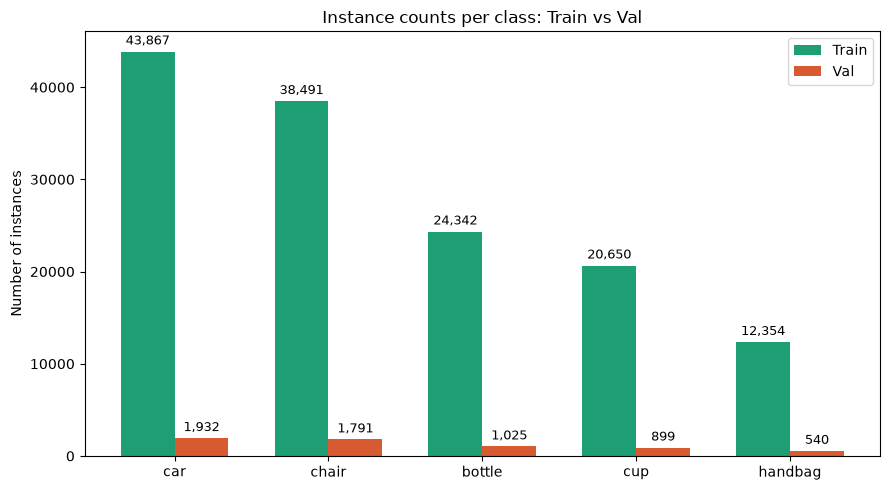

In [11]:
# --- Bar chart with exact instance counts labeled ---

chart_df = coco_stats_df[coco_stats_df["Class"].isin(selected_classes)].set_index("Class")
chart_df = chart_df.loc[selected_classes]

x_positions = range(len(selected_classes))
bar_width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

train_bars = ax.bar([x - bar_width/2 for x in x_positions], chart_df["Train Instances"],
                     width=bar_width, label="Train", color="#1D9E75")
val_bars = ax.bar([x + bar_width/2 for x in x_positions], chart_df["Val Instances"],
                   width=bar_width, label="Val", color="#D85A30")

# --- Print the exact number above each bar ---
for bar in train_bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + max(chart_df["Train Instances"])*0.01,
            f"{int(height):,}", ha="center", va="bottom", fontsize=9)

for bar in val_bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + max(chart_df["Train Instances"])*0.01,
            f"{int(height):,}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(list(x_positions))
ax.set_xticklabels(selected_classes)
ax.set_ylabel("Number of instances")
ax.set_title("Instance counts per class: Train vs Val")
ax.legend()

plt.tight_layout()
plt.show()

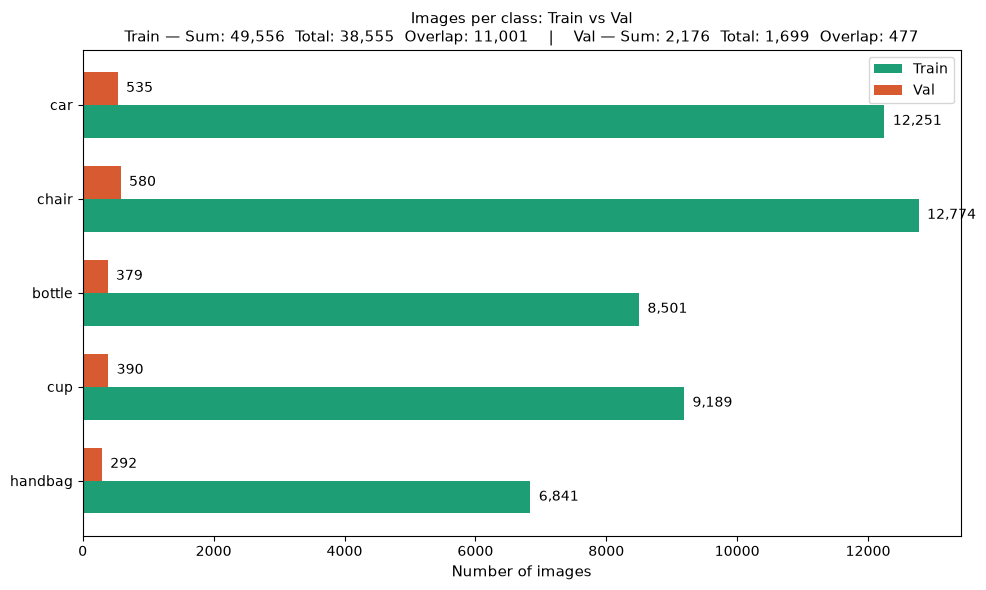

In [21]:
# --- Summary: images per class, Train vs Val, with sum/total/overlap check for each split ---

# Reverse lookup: new class index -> class name
index_to_class_name = {idx: name for name, idx in class_name_to_index.items()}

# --- Count images per class, done once per split ---
def count_images_per_class(annotations_by_image):
    counts = {name: 0 for name in selected_classes}
    for image_id, annotations in annotations_by_image.items():
        classes_in_this_image = set(
            index_to_class_name[category_id_to_new_index[ann["category_id"]]]
            for ann in annotations
        )
        for class_name in classes_in_this_image:
            counts[class_name] += 1
    return counts

train_images_per_class_count = count_images_per_class(train_annotations_by_image)
val_images_per_class_count = count_images_per_class(val_annotations_by_image)

# --- Sum check against actual total unique images, per split ---
train_sum = sum(train_images_per_class_count.values())
train_total = len(train_annotations_by_image)
train_difference = train_sum - train_total

val_sum = sum(val_images_per_class_count.values())
val_total = len(val_annotations_by_image)
val_difference = val_sum - val_total

# --- Grouped horizontal bar chart: Train and Val bars side by side per class ---
fig, ax = plt.subplots(figsize=(10, 6))

y_positions = range(len(selected_classes))
bar_height = 0.35

train_bars = ax.barh([y + bar_height/2 for y in y_positions],
                      [train_images_per_class_count[name] for name in selected_classes],
                      height=bar_height, label="Train", color="#1D9E75")
val_bars = ax.barh([y - bar_height/2 for y in y_positions],
                    [val_images_per_class_count[name] for name in selected_classes],
                    height=bar_height, label="Val", color="#D85A30")

# Print the exact count at the end of each bar
max_count = max(list(train_images_per_class_count.values()) + list(val_images_per_class_count.values()))
for bar, name in zip(train_bars, selected_classes):
    width = bar.get_width()
    ax.text(width + max_count * 0.01, bar.get_y() + bar.get_height()/2,
            f"{train_images_per_class_count[name]:,}", va="center", fontsize=10)
for bar, name in zip(val_bars, selected_classes):
    width = bar.get_width()
    ax.text(width + max_count * 0.01, bar.get_y() + bar.get_height()/2,
            f"{val_images_per_class_count[name]:,}", va="center", fontsize=10)

ax.set_yticks(list(y_positions))
ax.set_yticklabels(selected_classes)
ax.set_xlabel("Number of images", fontsize=11)
ax.set_title(
    f"Images per class: Train vs Val\n"
    f"Train — Sum: {train_sum:,}  Total: {train_total:,}  Overlap: {train_difference:,}    |    "
    f"Val — Sum: {val_sum:,}  Total: {val_total:,}  Overlap: {val_difference:,}",
    fontsize=11
)
ax.legend()
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [18]:
# --- Balance the 5 classes by undersampling (Train set only) ---
import random

random.seed(42)  # fixed seed so the same images get selected every time you rerun this

# --- Count current instances per class within the already-filtered train set ---
current_instance_counts = {name: 0 for name in selected_classes}
for image_id, annotations in train_annotations_by_image.items():
    for ann in annotations:
        class_name = index_to_class_name[category_id_to_new_index[ann["category_id"]]]
        current_instance_counts[class_name] += 1

print("Current instances per class (before balancing):")
for name in selected_classes:
    print(f"  {name}: {current_instance_counts[name]:,}")

# --- Undersampling target: the smallest class's instance count ---
target_instances = min(current_instance_counts.values())
print(f"\nTarget instances per class: {target_instances:,}")

# --- Go through images in random order, keeping one only if it doesn't push
#     any of its classes past the target ---
image_ids_shuffled = list(train_annotations_by_image.keys())
random.shuffle(image_ids_shuffled)

balanced_instance_counts = {name: 0 for name in selected_classes}
balanced_annotations_by_image = {}

for image_id in image_ids_shuffled:
    annotations = train_annotations_by_image[image_id]

    classes_in_image = set(
        index_to_class_name[category_id_to_new_index[ann["category_id"]]]
        for ann in annotations
    )

    # Keep this image only if EVERY class it contains still needs more instances
    if all(balanced_instance_counts[name] < target_instances for name in classes_in_image):
        balanced_annotations_by_image[image_id] = annotations
        for ann in annotations:
            class_name = index_to_class_name[category_id_to_new_index[ann["category_id"]]]
            balanced_instance_counts[class_name] += 1

print("\nFinal instances per class (after undersampling):")
for name in selected_classes:
    print(f"  {name}: {balanced_instance_counts[name]:,}")

print(f"\nImages kept: {len(balanced_annotations_by_image):,} out of {len(train_annotations_by_image):,}")

Current instances per class (before balancing):
  car: 43,867
  chair: 38,491
  bottle: 24,342
  cup: 20,650
  handbag: 12,354

Target instances per class: 12,354

Final instances per class (after undersampling):
  car: 12,361
  chair: 12,354
  bottle: 12,354
  cup: 12,354
  handbag: 9,022

Images kept: 18,559 out of 38,555


In [20]:
# --- Rebuild the train images/labels using only the balanced (undersampled) set ---

train_images_dir = dataset_root / "images" / "train"
train_labels_dir = dataset_root / "labels" / "train"

# Clear out the previously copied (full, unbalanced) train files first
for folder in [train_images_dir, train_labels_dir]:
    for f in folder.glob("*"):
        f.unlink()

# Reuse the same copy + label-writing function from Step 7, now pointed at the balanced set
build_dataset_split("train", coco_root / "train2017", train_image_info,
                     balanced_annotations_by_image, category_id_to_new_index)

print(f"Train folder rebuilt with {len(balanced_annotations_by_image):,} balanced images.")

Writing train set: 100%|██████████| 18559/18559 [01:23<00:00, 222.38it/s]

Train folder rebuilt with 18,559 balanced images.
